In [1]:
import os
import numpy as np
import torch
import util
import matplotlib.pyplot as plt
from data import fr
%matplotlib inline

In [2]:
fr_path = 'pretrained_models/DeepFreq/frequency_representation_module.pth'
fc_path = 'pretrained_models/DeepFreq/frequency_counting_module.pth'
data_dir = 'test_dataset'

# DeepFreq: a beginner-friendly walkthrough

This notebook demonstrates **DeepFreq**, a learned method for estimating the frequencies of several complex sinusoids from a short, noisy signal. It follows the pretrained-model example from the repository and explains each stage of the pipeline.

A simplified signal model is

$$y[t] = \sum_{k=1}^{K} a_k e^{j2\pi f_k t} + w[t],$$

where $K$ is the unknown number of sinusoids, $a_k$ is a complex amplitude, $f_k$ is a normalized frequency, and $w[t]$ is noise. The goal is to recover both **how many frequencies exist** and **where they are**. Frequencies here are normalized to the interval $[-0.5, 0.5)$.

## Pipeline at a glance

1. Load a noisy signal represented by separate real and imaginary channels.
2. The **frequency-representation (FR) module** converts the short signal into a dense, spectrum-like curve.
3. The **frequency-counting (FC) module** estimates $K$, the number of sinusoidal components.
4. `find_freq` selects the strongest local peaks in the learned representation.
5. Compare the result at different noise levels and against classical estimators.

The first two code cells import the libraries and set the paths to the pretrained checkpoints and bundled test data.

## 1. Begin with a simple signal

Before using the neural network, let us build the type of signal DeepFreq receives. One complex sinusoid traces a rotating point: its real channel behaves like a cosine and its imaginary channel behaves like a sine. A mixture is made by adding several such rotations sample by sample.

The pretrained model expects exactly 50 time samples. We first create one component at normalized frequency 0.05 cycles/sample, then add a weaker component at 0.25. Finally, we add reproducible Gaussian noise at 20 dB SNR.

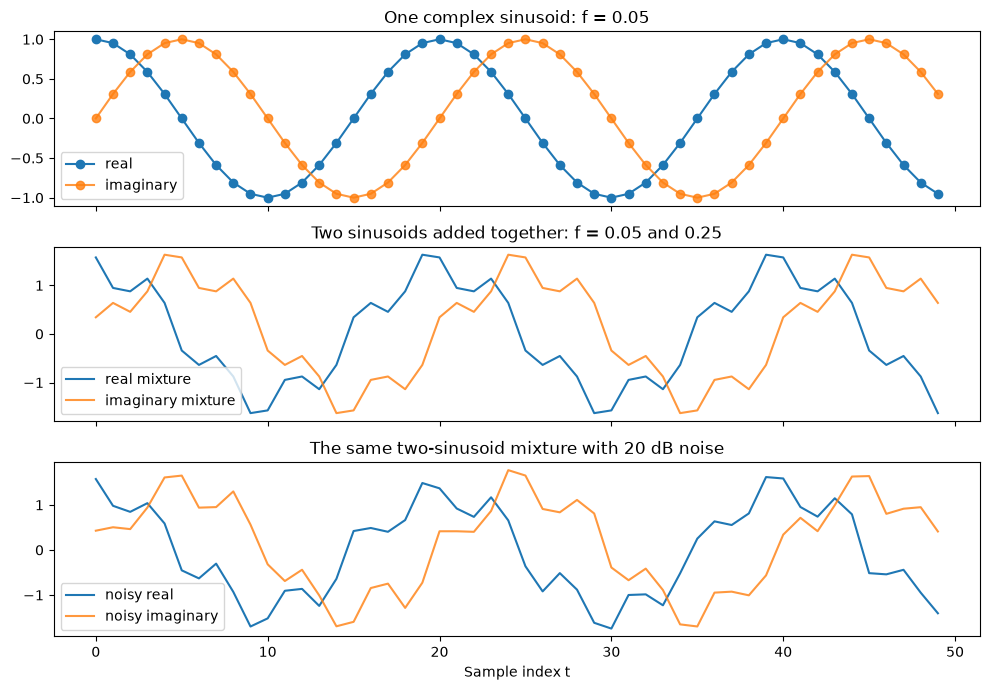

In [3]:
# Build one sinusoid, then a mixture of two sinusoids.
n_samples = 50
sample_index = np.arange(n_samples)
simple_true_freqs = np.array([0.05, 0.25])

component_1 = np.exp(2j * np.pi * simple_true_freqs[0] * sample_index)
component_2 = 0.3 * np.exp(1j * (2 * np.pi * simple_true_freqs[1] * sample_index + 1.0))
clean_complex = component_1 + component_2

# Match the RMS normalization used when DeepFreq's training data was generated.
clean_channels = np.stack([clean_complex.real, clean_complex.imag])
clean_channels /= np.sqrt(np.mean(clean_channels ** 2))

# Add Gaussian noise with a fixed seed so the example is repeatable.
rng = np.random.default_rng(7)
noise = rng.normal(size=clean_channels.shape)
noise *= np.linalg.norm(clean_channels) / (np.linalg.norm(noise) * 10 ** (20 / 20))
noisy_channels = clean_channels + noise

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
axes[0].plot(sample_index, component_1.real, 'o-', label='real')
axes[0].plot(sample_index, component_1.imag, 'o-', label='imaginary', alpha=0.8)
axes[0].set_title('One complex sinusoid: f = 0.05')
axes[0].legend()
axes[1].plot(sample_index, clean_channels[0], label='real mixture')
axes[1].plot(sample_index, clean_channels[1], label='imaginary mixture', alpha=0.8)
axes[1].set_title('Two sinusoids added together: f = 0.05 and 0.25')
axes[1].legend()
axes[2].plot(sample_index, noisy_channels[0], label='noisy real')
axes[2].plot(sample_index, noisy_channels[1], label='noisy imaginary', alpha=0.8)
axes[2].set_title('The same two-sinusoid mixture with 20 dB noise')
axes[2].set_xlabel('Sample index t')
axes[2].legend()
fig.tight_layout()

### Map the complex signal to model input

PyTorch neural networks operate on real-valued tensors here, so a complex vector of length 50 becomes two rows: row 0 contains real values and row 1 contains imaginary values. A leading batch dimension is then added.

Thus the mapping is `(50 complex samples) → (2 channels, 50 samples) → (1 example, 2 channels, 50 samples)`. The model input shape is `(batch, channel, time)`.

Complex signal shape:        (50,)
Two-channel signal shape:    (2, 50)
Batched model-input shape:  (1, 2, 50)
Meaning: 1 example, 2 channels (real/imaginary), 50 time samples


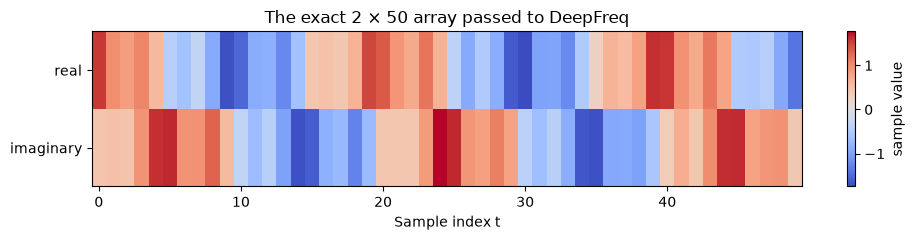

In [4]:
simple_input = noisy_channels.astype(np.float32)[None, :, :]
print('Complex signal shape:       ', clean_complex.shape)
print('Two-channel signal shape:   ', noisy_channels.shape)
print('Batched model-input shape: ', simple_input.shape)
print('Meaning: 1 example, 2 channels (real/imaginary), 50 time samples')

fig, ax = plt.subplots(figsize=(10, 2.5))
image = ax.imshow(simple_input[0], aspect='auto', cmap='coolwarm')
ax.set_yticks([0, 1], labels=['real', 'imaginary'])
ax.set_xlabel('Sample index t')
ax.set_title('The exact 2 × 50 array passed to DeepFreq')
fig.colorbar(image, ax=ax, label='sample value')
fig.tight_layout()

## 2. Load the pretrained DeepFreq modules

PyTorch uses a CUDA GPU when one is available; otherwise it uses the CPU. This small inference example runs comfortably on CPU. The FR checkpoint learns the signal-to-curve mapping; the FC checkpoint learns the curve-to-count mapping.

In [5]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [6]:
#load models
fr_module, _, _, args_fr, _ = util.load(fr_path, 'fr', device)
fc_module, _, _, args_fc, _ = util.load(fc_path, 'fc', device)
fr_module.cpu()
fr_module.eval()
fc_module.cpu()
fc_module.eval()
# Find an FR input length that makes fc_module.mod produce the expected flattened size
def _find_target_fr_size(fc_mod, minL=50, maxL=2000):
    import torch
    for L in range(minL, maxL+1):
        x = torch.zeros(1,1,L)
        for layer in fc_mod.mod:
            x = layer(x)
        if x.view(1,-1).shape[1] == fc_mod.out_layer.in_features:
            return L
    raise RuntimeError('No compatible FR size found for fc_module')
target_fr_size = _find_target_fr_size(fc_module)
print('Using target_fr_size for fc input:', target_fr_size)
xgrid = np.linspace(-0.5, 0.5, fr_module.fr_size, endpoint=False)

Using target_fr_size for fc input: 780


## 3. Walk the simple example through DeepFreq

Now we send the `(1, 2, 50)` tensor through the full inference pipeline:

1. The FR module maps 100 input numbers (50 real + 50 imaginary) to a dense curve over 1,000 candidate frequencies.
2. The older FC checkpoint expects a compatible internal length, so the curve is resampled before counting. This changes only the counter's input; peak locations still use the original 1,000-point curve.
3. The FC output is a real-valued regression, so it is rounded to an integer count.
4. `find_freq` returns the strongest local peaks from the FR curve.

For this constructed example, we know that the correct answer is two frequencies: 0.05 and 0.25.

In [7]:
import torch.nn.functional as F

simple_tensor = torch.from_numpy(simple_input)
with torch.no_grad():
    simple_fr_tensor = fr_module(simple_tensor)
    simple_fr_for_counting = F.interpolate(
        simple_fr_tensor[:, None, :], size=target_fr_size,
        mode='linear', align_corners=False
    )[:, 0, :]
    simple_count_raw = fc_module(simple_fr_for_counting).item()

simple_count = int(np.clip(np.round(simple_count_raw), 1, 10))
simple_fr = simple_fr_tensor.numpy()
simple_estimates = fr.find_freq(simple_fr, np.array([simple_count]), xgrid)[0]
simple_estimates = simple_estimates[simple_estimates > -1]

print('Input tensor shape:          ', tuple(simple_tensor.shape))
print('FR output shape:             ', tuple(simple_fr_tensor.shape))
print('Raw FC output:               ', round(simple_count_raw, 3))
print('Rounded frequency count:     ', simple_count)
print('True frequencies:            ', simple_true_freqs)
print('Estimated peak frequencies:  ', simple_estimates)

Input tensor shape:           (1, 2, 50)
FR output shape:              (1, 1000)
Raw FC output:                1.994
Rounded frequency count:      2
True frequencies:             [0.05 0.25]
Estimated peak frequencies:   [0.05  0.249]


### Read the output visually

The network's output is not a reconstructed time signal. It is a **frequency representation**: the horizontal axis is candidate frequency and the vertical axis is learned evidence. The two large peaks should align with the known frequencies. Dashed black lines show truth and red lines show the peaks selected by the algorithm.

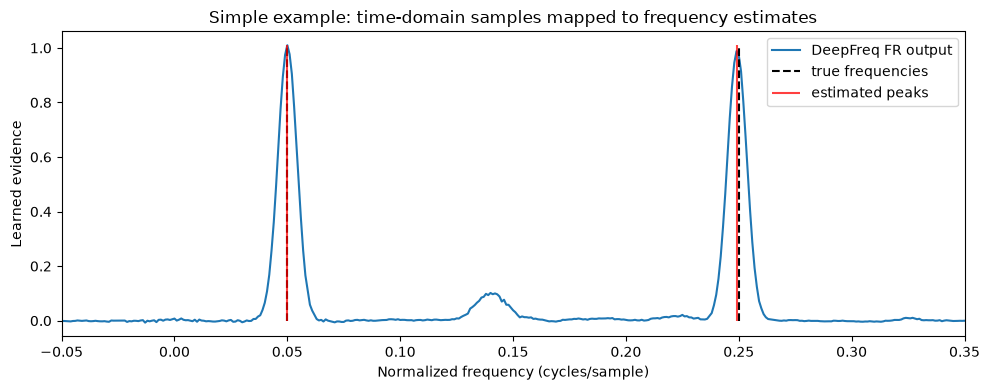

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(xgrid, simple_fr[0], label='DeepFreq FR output')
ax.vlines(simple_true_freqs, 0, simple_fr[0].max(), colors='black',
          linestyles='--', label='true frequencies')
ax.vlines(simple_estimates, 0, simple_fr[0].max(), colors='red',
          alpha=0.75, label='estimated peaks')
ax.set_xlim(-0.05, 0.35)
ax.set_xlabel('Normalized frequency (cycles/sample)')
ax.set_ylabel('Learned evidence')
ax.set_title('Simple example: time-domain samples mapped to frequency estimates')
ax.legend()
fig.tight_layout()

### What just happened?

The raw 20 dB signal looked complicated because two rotating sinusoids and noise were mixed together. DeepFreq transformed those samples into a representation with isolated peaks, predicted how many peaks to keep, and mapped their grid positions back to frequencies. This is the same sequence used below on the repository's harder test examples.

## 4. Load the bundled test data

The dataset contains the same underlying examples at 0, 10, and 50 dB SNR. A larger dB value means less noise. `f.npy` stores ground-truth frequencies; unused positions contain sentinel values below $-0.5$.

In [9]:
#load data
f = np.load(os.path.join(data_dir, 'f.npy'))
signal_0dB = np.load(os.path.join(data_dir, '0.0dB.npy'))
signal_10dB = np.load(os.path.join(data_dir, '10.0dB.npy'))
signal_50dB = np.load(os.path.join(data_dir, '50.0dB.npy'))
nfreq = nfreq = np.sum(f >= -0.5, axis=1)

## 5. Apply the same pipeline to a bundled test example

DeepFreq uses two trained neural networks. The FR module produces one value for every point of `xgrid`; peaks should occur near sinusoid frequencies. The FC module maps that representation to an estimated source count. Both models are placed in evaluation mode so batch-normalization layers use their learned statistics.

The compatibility code finds the representation length expected by this older counting checkpoint and linearly resamples the FR output before counting. This is needed because current PyTorch convolution behavior differs from the environment used to create the checkpoint.

The following cells repeat the same steps on repository example `idx = 8` at three noise levels. Adding `[None]` creates a batch dimension, changing one signal from shape `(2, signal_length)` to `(1, 2, signal_length)`. `torch.no_grad()` disables gradient tracking because we are performing inference, not training.

In [10]:
idx = 8

In [11]:
with torch.no_grad():
    fr_0dB = fr_module(torch.tensor(signal_0dB[idx][None]))
    fr_10dB = fr_module(torch.tensor(signal_10dB[idx][None]))
    fr_50dB = fr_module(torch.tensor(signal_50dB[idx][None]))
    # Resample frequency representation to match fc_module expected input size if needed
    import torch.nn.functional as F
    try:
        target_size = target_fr_size
    except Exception:
        target_size = fr_0dB.shape[-1]
    def _resample(frvec, target):
        t = frvec.unsqueeze(1)  # shape [bsz, 1, L]
        t = F.interpolate(t, size=target, mode='linear', align_corners=False)
        return t.squeeze(1)
    fr_0dB_rs = _resample(fr_0dB, target_size)
    fr_10dB_rs = _resample(fr_10dB, target_size)
    fr_50dB_rs = _resample(fr_50dB, target_size)
    nestimate_0dB = fc_module(fr_0dB_rs).numpy().round()
    nestimate_10dB = fc_module(fr_10dB_rs).numpy().round()
    nestimate_50dB = fc_module(fr_50dB_rs).numpy().round()
fr_0dB = fr_0dB.numpy()    
fr_10dB = fr_10dB.numpy()    
fr_50dB = fr_50dB.numpy()

### Check the true number of frequencies

For learning purposes we can inspect the answer stored in the test set. This is only ground truth for evaluation—the model does not receive it as input.

In [12]:
nfreq[idx]

np.int64(9)

### Compare the estimated counts

The next tuple reports the rounded FC-module prediction at 0, 10, and 50 dB. The estimate need not be perfect, especially when peaks overlap or noise masks weak components. Since the later peak-selection step uses this count, a count error can also cause missed or extra frequency estimates.

In [13]:
nestimate_0dB[0, 0], nestimate_10dB[0, 0], nestimate_50dB[0, 0]

(np.float32(7.0), np.float32(6.0), np.float32(7.0))

### Convert the learned curve into frequency estimates

The FR network outputs a dense curve rather than a list of frequencies. `fr.find_freq` finds local maxima and keeps the requested number of strongest peaks. Each peak index is converted into a normalized frequency using `xgrid`. The result is therefore a **fine-grid estimate**, rather than direct regression of an unordered frequency list.

In [14]:
# Ensure nestimate arrays are 1-D integer arrays
import numpy as _np
nestimate_0dB = _np.asarray(nestimate_0dB).round().astype(int).reshape(-1)
nestimate_10dB = _np.asarray(nestimate_10dB).round().astype(int).reshape(-1)
nestimate_50dB = _np.asarray(nestimate_50dB).round().astype(int).reshape(-1)
f_estimate_0dB = fr.find_freq(fr_0dB, nestimate_0dB, xgrid)
f_estimate_10dB = fr.find_freq(fr_10dB, nestimate_10dB, xgrid)
f_estimate_50dB = fr.find_freq(fr_50dB, nestimate_50dB, xgrid)

### Result at 50 dB

At 50 dB there is very little noise. The blue curve is DeepFreq's learned representation, red vertical lines are estimated frequencies, and dashed black lines are ground truth. Good estimates place red lines close to black lines.

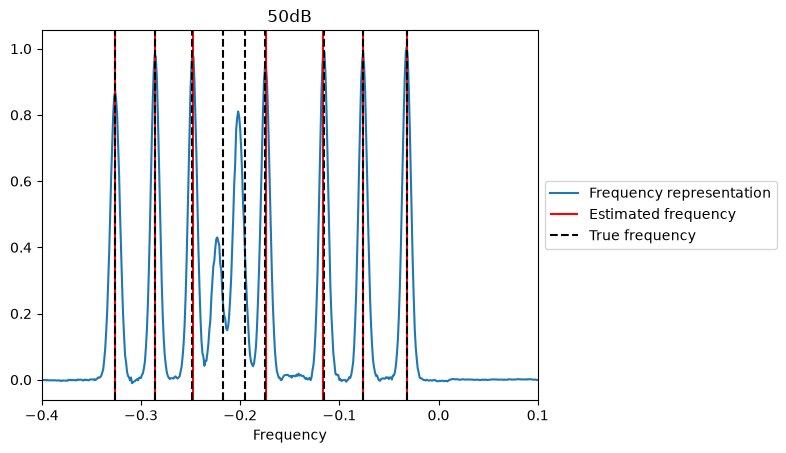

In [15]:
fig, ax = plt.subplots()
ax.plot(xgrid, fr_50dB[0], label='Frequency representation')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
f_model = f_estimate_50dB[f_estimate_50dB > -1]
ax.vlines(f_model, ymin=ylim[0], ymax=ylim[1], color='r', label='Estimated frequency')
ax.vlines(ff, linestyle='--', ymin=ylim[0], ymax=ylim[1], color='k', label='True frequency')
ax.set_ylim(ylim)
ax.set_xlim(-0.4, 0.1)
ax.set_xlabel('Frequency')
ax.set_title('50dB')
ax.legend( loc='center left', bbox_to_anchor=(1, 0.5))

### Result at 10 dB

At 10 dB, noise perturbs the input more strongly. Look for peaks that become wider, lower, merged, or shifted compared with the 50 dB plot.

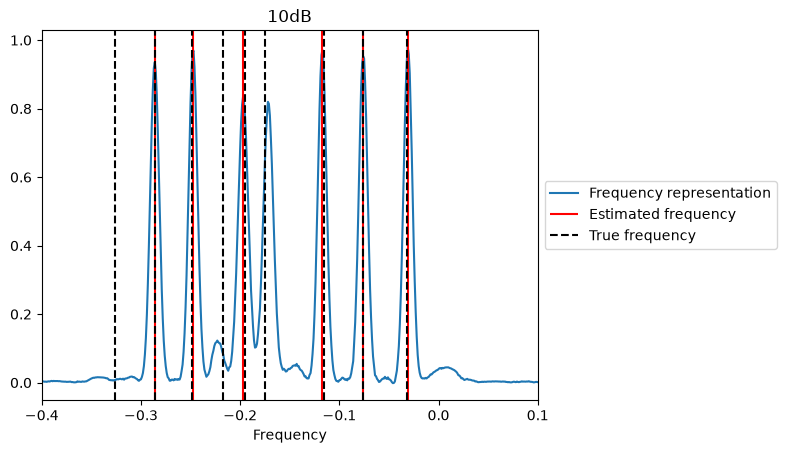

In [16]:
fig, ax = plt.subplots()
ax.plot(xgrid, fr_10dB[0], label='Frequency representation')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
f_model = f_estimate_10dB[f_estimate_10dB > -1]
ax.vlines(f_model, ymin=ylim[0], ymax=ylim[1], color='r', label='Estimated frequency')
ax.vlines(ff, linestyle='--', ymin=ylim[0], ymax=ylim[1], color='k', label='True frequency')
ax.set_ylim(ylim)
ax.set_xlim(-0.4, 0.1)
ax.set_xlabel('Frequency')
ax.set_title('10dB')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

### Result at 0 dB

At 0 dB the signal and noise powers are equal. This is a difficult regime: weak sinusoids can disappear and nearby components can become indistinguishable.

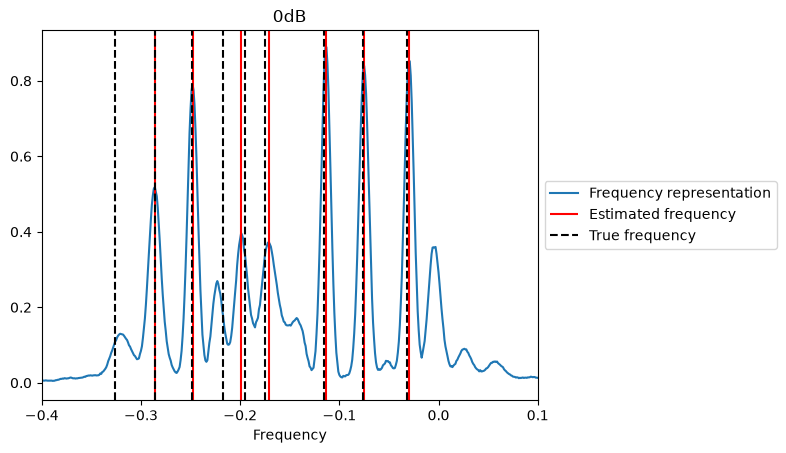

In [17]:
fig, ax = plt.subplots()
ax.plot(xgrid, fr_0dB[0], label='Frequency representation')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
f_model = f_estimate_0dB[f_estimate_0dB > -1]
ax.vlines(f_model, ymin=ylim[0], ymax=ylim[1], color='r', label='Estimated frequency')
ax.vlines(ff, linestyle='--', ymin=ylim[0], ymax=ylim[1], color='k', label='True frequency')
ax.set_ylim(ylim)
ax.set_xlim(-0.4, 0.1)
ax.set_xlabel('Frequency')
ax.set_title('0dB')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

## 6. Study the impact of noise

This section selects another signal (`idx = 13`) and overlays its learned representations at three SNRs. Because the clean sinusoidal content is the same, differences among the curves are caused by noise. A robust estimator should retain peaks near the dashed ground-truth lines as SNR decreases.

In [18]:
idx = 13
with torch.no_grad():
    fr_0dB = fr_module(torch.tensor(signal_0dB[idx][None])).numpy()[0]
    fr_10dB = fr_module(torch.tensor(signal_10dB[idx][None])).numpy()[0]
    fr_50dB = fr_module(torch.tensor(signal_50dB[idx][None])).numpy()[0]

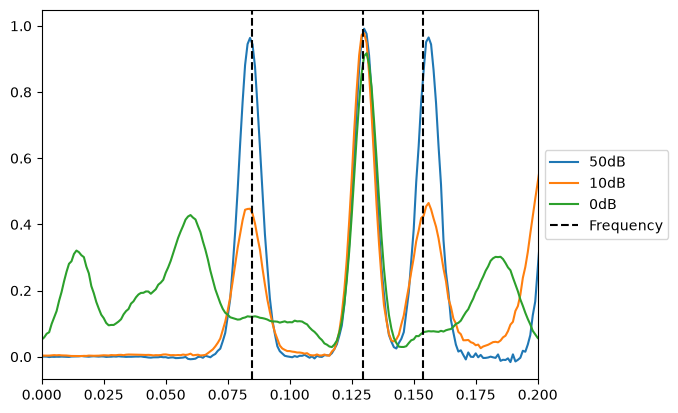

In [19]:
fig, ax = plt.subplots()
ax.plot(xgrid, fr_50dB, label='50dB')
ax.plot(xgrid, fr_10dB, label='10dB')
ax.plot(xgrid, fr_0dB, label='0dB')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
ax.vlines(ff, ymin=ylim[0], ymax=ylim[1], linestyle='--', color='k', label='Frequency')
ax.set_ylim(ylim)
ax.set_xlim(0., 0.2)
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

## 7. Compare DeepFreq with classical spectral estimators

The test arrays store real and imaginary parts in two channels. The next cell reconstructs complex samples with `real + 1j * imaginary`, which is the input form expected by the classical methods.

The comparison includes:

- **Periodogram:** evaluates Fourier energy on a grid. It is simple, but its resolution is limited for short signals and close frequencies.
- **MUSIC:** uses an eigenspace decomposition to separate signal and noise subspaces. It can resolve close frequencies, but here it is given the true source count.
- **CBLasso:** a continuous sparse-recovery baseline requiring MATLAB and CVX; it is optional in this notebook.
- **DeepFreq:** uses the learned FR network and does not require an eigendecomposition at inference time.

This is a visual, single-example comparison—not a full benchmark. Quantitative evaluation should average a matching error over many test signals and SNR levels.

In [20]:
idx = 13

In [21]:
signal_50dB_c = signal_50dB[:, 0]+ 1j * signal_50dB[:, 1]
signal_10dB_c = signal_10dB[:, 0]+ 1j * signal_10dB[:, 1]

In [22]:
with torch.no_grad():
    fr_10dB = fr_module(torch.tensor(signal_10dB[idx][None]))[0]
    fr_50dB = fr_module(torch.tensor(signal_50dB[idx][None]))[0]
music_fr_10dB = fr.music(signal_10dB_c[idx][None], xgrid, nfreq[idx][None])[0]
periodogram_10dB = fr.periodogram(signal_10dB_c[idx][None], xgrid)[0]
music_fr_50dB = fr.music(signal_50dB_c[idx][None], xgrid, nfreq[idx][None])[0]
periodogram_50dB = fr.periodogram(signal_50dB_c[idx][None], xgrid)[0]

fr_10dB = fr_10dB.cpu().data.numpy()
fr_50dB = fr_50dB.cpu().data.numpy()

### Optional CBLasso setup

CBLasso is disabled by default because it requires MATLAB, the MATLAB Engine for Python, and CVX. The periodogram, MUSIC, and DeepFreq comparisons run without MATLAB. Set `cbl = True` only after installing those dependencies.

In [23]:
# Disable CBLasso MATLAB dependency when matlab.engine is not available
cbl = False
if cbl:
    import sys
    # sys.path.append('/usr/local/lib/python3.5/dist-packages/')
    import matlab.engine
    eng = matlab.engine.start_matlab()
    eng.cd(r'cblasso')

In [24]:
if cbl:
    res_10dB = eng.polynomial(matlab.double(list(signal_10dB_c[idx]), is_complex=True))
    res_10dB = np.asarray(res_10dB)
    cbl_10dB = np.roll(res_10dB[:, 0], fr_module.fr_size//2)
    res_50dB = eng.polynomial(matlab.double(list(signal_50dB_c[idx]), is_complex=True))
    res_50dB = np.asarray(res_50dB)
    cbl_50dB = np.roll(res_50dB[:, 0], fr_module.fr_size//2)
    grid = np.roll(res_50dB[:, 1], fr_module.fr_size//2)
    grid[grid >= 0.5] -= 1

### Baseline comparison at 50 dB

Each graph uses the same ground-truth markers. Compare peak sharpness and whether each method separates nearby components. Note that the vertical scale differs between methods, so peak locations matter more than absolute heights.

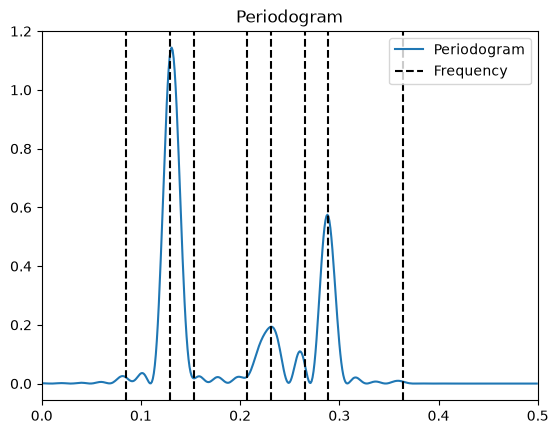

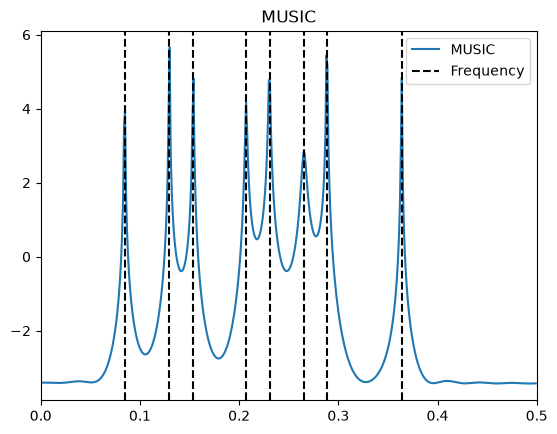

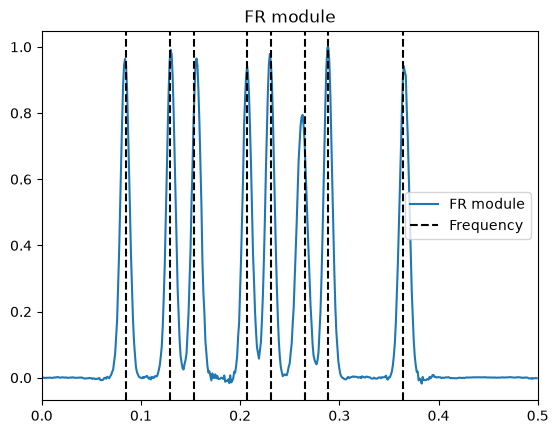

In [25]:
fig, ax = plt.subplots()
ax.plot(xgrid, periodogram_50dB, label='Periodogram')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
ax.vlines(ff, ymin=ylim[0], ymax=ylim[1], linestyle='--', color='k', label='Frequency')
ax.set_ylim(ylim)
ax.set_xlim(0, 0.5)
ax.set_title('Periodogram')
ax.legend()
plt.show()

fig, ax = plt.subplots()
ax.plot(xgrid, music_fr_50dB, label='MUSIC')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
ax.vlines(ff, ymin=ylim[0], ymax=ylim[1], linestyle='--', color='k', label='Frequency')
ax.set_ylim(ylim)
ax.set_xlim(0, 0.5)
ax.set_title('MUSIC')
ax.legend()
plt.show()

if cbl:
    fig, ax = plt.subplots()
    ax.plot(grid, np.abs(cbl_50dB), label='CBLasso')
    ylim = ax.get_ylim()
    ff = f[idx][f[idx] > -1]
    ax.vlines(ff, ymin=ylim[0], ymax=ylim[1], linestyle='--', color='k', label='Frequency')
    ax.set_ylim(ylim)
    ax.set_xlim(0, 0.5)
    ax.set_title('CBLasso')
    ax.legend()
    plt.show()

fig, ax = plt.subplots()
ax.plot(xgrid, fr_50dB, label='FR module')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
ax.vlines(ff, ymin=ylim[0], ymax=ylim[1], linestyle='--', color='k', label='Frequency')
ax.set_ylim(ylim)
ax.set_xlim(0, 0.5)
ax.set_title('FR module')
ax.legend()
plt.show()

### Baseline comparison at 10 dB

Repeat the comparison under stronger noise. MUSIC receives the true number of frequencies in this demonstration, whereas the complete DeepFreq pipeline estimates the count with its FC module. Keep that difference in mind when interpreting the plots.

## What to try next

- Change `idx` to inspect other test signals.
- Load another SNR file from `test_dataset`.
- Print tensor shapes after each stage to connect the mathematics to the implementation.
- Compare estimated and true frequencies numerically rather than only visually.
- Read `modules.py` to see the convolutional FR and counting architectures, then `data/fr.py` to inspect peak extraction and classical baselines.

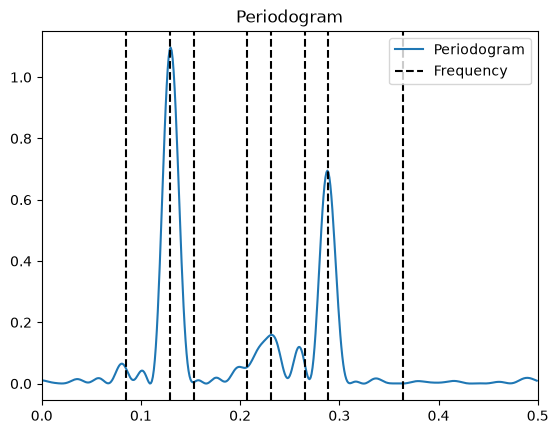

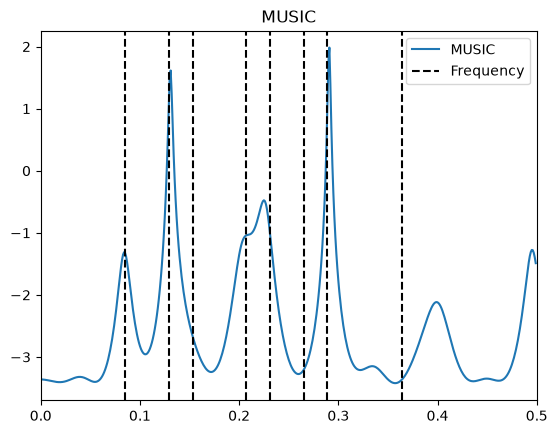

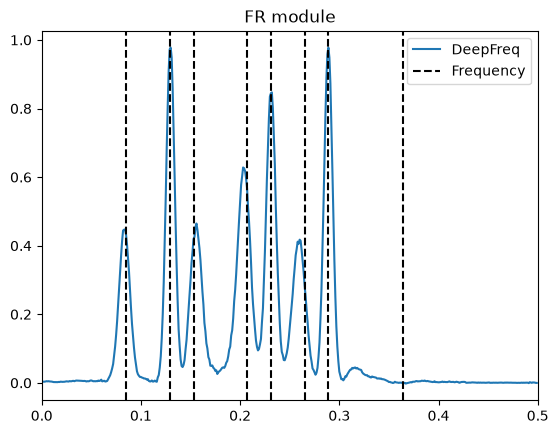

In [26]:
fig, ax = plt.subplots()
ax.plot(xgrid, periodogram_10dB, label='Periodogram')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
ax.vlines(ff, ymin=ylim[0], ymax=ylim[1], linestyle='--', color='k', label='Frequency')
ax.set_ylim(ylim)
ax.set_xlim(0, 0.5)
ax.set_title('Periodogram')
ax.legend()
plt.show()

fig, ax = plt.subplots()
ax.plot(xgrid, music_fr_10dB, label='MUSIC')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
ax.vlines(ff, ymin=ylim[0], ymax=ylim[1], linestyle='--', color='k', label='Frequency')
ax.set_ylim(ylim)
ax.set_xlim(0, 0.5)
ax.set_title('MUSIC')
ax.legend()
plt.show()

if cbl:
    fig, ax = plt.subplots()
    ax.plot(grid, np.abs(cbl_10dB), label='CBLasso')
    ylim = ax.get_ylim()
    ff = f[idx][f[idx] > -1]
    ax.vlines(ff, ymin=ylim[0], ymax=ylim[1], linestyle='--', color='k', label='Frequency')
    ax.set_ylim(ylim)
    ax.set_xlim(0, 0.5)
    ax.set_title('CBLasso')
    ax.legend()
    plt.show()

fig, ax = plt.subplots()
ax.plot(xgrid, fr_10dB, label='DeepFreq')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
ax.vlines(ff, ymin=ylim[0], ymax=ylim[1], linestyle='--', color='k', label='Frequency')
ax.set_ylim(ylim)
ax.set_xlim(0, 0.5)
ax.set_title('FR module')
ax.legend()
plt.show()